# Solutions to the exercises of Chapter 11

**Chapter:** [11. Lattice models and phase transitions: 2D Ising (Metropolis vs Wolff cluster)](../../notebooks/part3_monte_carlo/11_ising_metropolis_vs_wolff.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
T_grid = np.array([1.6, 2.0, 2.27, 2.6, 3.2])
m_avg, e_avg = [], []
for T_v in T_grid:
    spins = np.ones((16, 16), dtype=int)
    beta_v = 1.0 / T_v
    for _ in range(40):
        spins, _ = es.ising_2d_wolff_step(spins, beta_v, rng)
    ms, es_l = [], []
    for _ in range(60):
        spins, _ = es.ising_2d_wolff_step(spins, beta_v, rng)
        ev, mv = es.ising_2d_energy_mag(spins)
        es_l.append(ev); ms.append(mv)
    e_avg.append(float(np.mean(es_l))); m_avg.append(float(np.mean(ms)))

Onsager T_c = 2.269185; <|m|> across T = [1.6  2.   2.27 2.6  3.2 ]: [0.982 0.918 0.599 0.293 0.164]


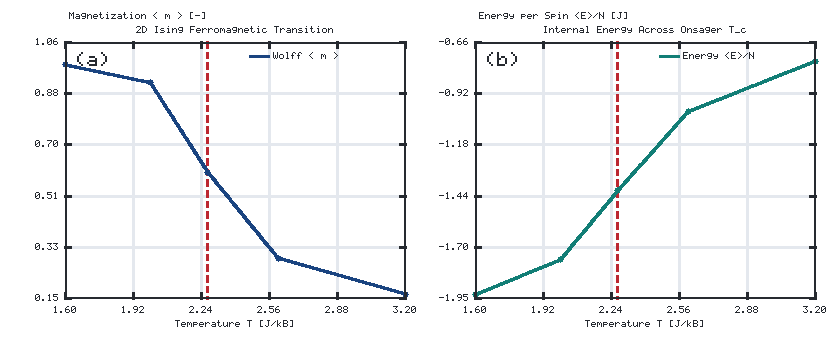

In [3]:
Tc = es.reference.ONSAGER_TC_2D_ISING
print(f"Onsager T_c = {Tc:.6f}; <|m|> across T = {T_grid}: {np.round(m_avg, 3)}")
assert m_avg[0] > 0.90 and m_avg[-1] < 0.30

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(T_grid, m_avg, "bo-", label="Wolff <|m|>")
ax1.axvline(Tc, color="r")
ax1.set_xlabel("Temperature T [J/kB]"); ax1.set_ylabel("Magnetization <|m|> [-]")
ax1.set_title("(a) 2D Ising Ferromagnetic Transition"); panel_label(ax1, "(a)")

ax2.plot(T_grid, e_avg, "gs-", label="Energy <E>/N")
ax2.axvline(Tc, color="r")
ax2.set_xlabel("Temperature T [J/kB]"); ax2.set_ylabel("Energy per Spin <E>/N [J]")
ax2.set_title("(b) Internal Energy Across Onsager T_c"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 11
e_gs, m_gs = es.ising_2d_energy_mag(np.ones((16, 16), dtype=int))
assert np.isclose(e_gs, -2.0) and np.isclose(m_gs, 1.0)
s_m = np.ones((12, 12), dtype=int)
for _ in range(80):
    s_m = es.ising_2d_metropolis_sweep(s_m, 1.0 / 2.6, rng)
e_m, _ = es.ising_2d_energy_mag(s_m)
print(f"Ch 11 Exercises — Metropolis energy at T=2.6: {e_m:.3f} (Wolff: {e_avg[3]:.3f})")
assert abs(e_m - e_avg[3]) < 0.45

Ch 11 Exercises — Metropolis energy at T=2.6: -0.833 (Wolff: -1.012)
